# 04 — Pass Depth & Accuracy: Brady vs. Mahomes

**Research question:** How did Brady and Mahomes distribute their pass attempts across target depths, and how successfully did they execute throws relative to model expectations?

**Predefined comparison windows (within the first 131 regular-season starts):**

- **Tom Brady:** 2006–2010; **53 starts**, including only one game in 2008 and four in 2010.
- **Patrick Mahomes:** 2018–2021; **62 starts**, ending before Tyreek Hill's departure.

This is **not** a comparison of two complete, equal-length career periods or a causal evaluation of quarterback skill. All values use previously validated official-style pass attempts; sacks, scrambles, and two-point attempts are not target-depth throws. Results are descriptive and not adjusted for every aspect of offensive context.

## 1. Data loading and integrity checks

Run `python3 scripts/build_pass_depth_cpoe.py` from the repository root first. It uses the same pass-attempt selection rules as the audited passing statistics pipeline and checks reconciliation against `qb_game_stats.parquet`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path("../data/processed")
FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

summary = pd.DataFrame(pl.read_parquet(DATA / "qb_pass_depth_summary.parquet").to_dicts())
seasons = pd.DataFrame(pl.read_parquet(DATA / "qb_pass_depth_by_season.parquet").to_dicts())
games = pd.DataFrame(pl.read_parquet(DATA / "qb_pass_depth_by_game.parquet").to_dicts())

ORDER = ["Behind LOS", "0–5", "6–10", "11–19", "20+"]
PLAYERS = ["Tom Brady", "Patrick Mahomes"]
COLORS = {"Tom Brady": "#002244", "Patrick Mahomes": "#E31837"}

assert set(summary.player_name) == set(PLAYERS)
assert summary.groupby("player_name")["attempt_share_pct"].sum().between(99.999,100.001).all()
assert (summary["modeled_attempts"] <= summary["attempts"]).all()
assert np.allclose(summary["modeled_completion_pct"] - summary["expected_completion_pct"], summary["cpoe_pp"], atol=1e-8)

counts = (games[["player_name", "game_id"]].drop_duplicates()
          .groupby("player_name").size())
assert counts["Tom Brady"] == 53 and counts["Patrick Mahomes"] == 62

pd.options.display.float_format = "{:,.2f}".format
print("Pass attempts by player:")
display(summary.groupby("player_name")[["attempts", "modeled_attempts", "epa_attempts"]].sum())
print("Starts in the comparison:")
display(counts.rename("starts"))

Pass attempts by player:


,attempts,modeled_attempts,epa_attempts
player_name,,,
Patrick Mahomes,2309,2221,2309
Tom Brady,1793,1767,1793


Starts in the comparison:


player_name
Patrick Mahomes    62
Tom Brady          53
Name: starts, dtype: int64

### Depth zones and metric definitions

| Zone | `air_yards` | Meaning |
|---|---|---|
| Behind LOS | below 0 | Throws behind the line of scrimmage |
| 0–5 | 0 to 5 | Very short throws |
| 6–10 | 6 to 10 | Short-to-intermediate throws |
| 11–19 | 11 to 19 | Intermediate throws |
| 20+ | 20 or more | Deep throws |

- **Attempt share:** zone attempts ÷ all attempts with measured air yards.
- **Completion percentage:** completed throws ÷ all throws in the depth zone.
- **QB EPA per attempt:** summed `qb_epa` ÷ zone attempts with available EPA, **not** EPA per dropback.
- **CPOE (percentage points):** `100 × mean(completion − cp)` over exactly those throws with modeled completion probability. Source `cpoe` was checked to have percentage-point units.

A `cp`-missing throw remains eligible for the first two metrics if its depth is known; it is **not** treated as having zero CPOE. For comparison of actual and expected completion, use `modeled_completion_pct`, not the completion percentage calculated from all attempts.

## 2. Exact study-window results

In [2]:
names = {
    "attempts": "Attempts",
    "attempt_share_pct": "Attempt share (%)",
    "completions": "Completions",
    "completion_pct": "Completion (%)",
    "modeled_attempts": "CP N",
    "cp_coverage_pct": "CP coverage (%)",
    "expected_completion_pct": "Expected completion (%)",
    "modeled_completion_pct": "Observed, CP sample (%)",
    "cpoe_pp": "CPOE (pp)",
    "qb_epa_per_attempt": "QB EPA / attempt",
}
view = (summary.set_index(["player_name", "depth_zone"])
        .reindex(pd.MultiIndex.from_product([PLAYERS, ORDER], names=["player_name", "depth_zone"]))
        [list(names)].rename(columns=names))
display(view.round(2))

Attempts  Attempt share (%)  Completions  \
player_name     depth_zone                                             
Tom Brady       Behind LOS       200              11.15       167.00   
                0–5              761              42.44       553.00   
                6–10             331              18.46       229.00   
                11–19            299              16.68       158.00   
                20+              202              11.27        74.00   
Patrick Mahomes Behind LOS       417              18.06       360.00   
                0–5              723              31.31       529.00   
                6–10             445              19.27       284.00   
                11–19            420              18.19       233.00   
                20+              304              13.17       122.00   

                            Completion (%)  CP N  CP coverage (%)  \
player_name     depth_zone                                          
Tom Brady       Behind LOS           83.50   193            96.50   
                0–5                  72.67   750            98.55   
                6–10                 69.18   328            99.09   
                11–19                52.84   297            99.33   
                20+                  36.63   199            98.51   
Patrick Mahomes Behind LOS           86.33   410            98.32   
                0–5                  73.17   688            95.16   
                6–10                 63.82   432            97.08   
                11–19                55.48   395            94.05   
                20+                  40.13   296            97.37   

                            Expected completion (%)  Observed, CP sample (%)  \
player_name     depth_zone                                                     
Tom Brady       Behind LOS                    80.04                    84.46   
                0–5                           68.35                    73.33   
                6–10                          61.77                    69.82   
                11–19                         53.25                    52.86   
                20+                           32.46                    36.68   
Patrick Mahomes Behind LOS                    85.21                    87.80   
                0–5                           72.30                    76.89   
                6–10                          65.84                    65.74   
                11–19                         56.44                    58.99   
                20+                           35.29                    41.22   

                            CPOE (pp)  QB EPA / attempt  
player_name     depth_zone                               
Tom Brady       Behind LOS       4.42              0.21  
                0–5              4.98              0.23  
                6–10             8.04              0.48  
                11–19           -0.39              0.41  
                20+              4.23              0.60  
Patrick Mahomes Behind LOS       2.59              0.14  
                0–5              4.59              0.24  
                6–10            -0.10              0.32  
                11–19            2.55              0.56  
                20+              5.93              0.78

## 3. Attempt share by target depth

**Question:** Which throwing depths accounted for each quarterback's passing volume?

Attempt share uses only throws with valid air yards. The upstream audit found one Mahomes 2020 throw without `air_yards`; it is excluded from the zone denominator but retained in the overall official-attempt reconciliation.

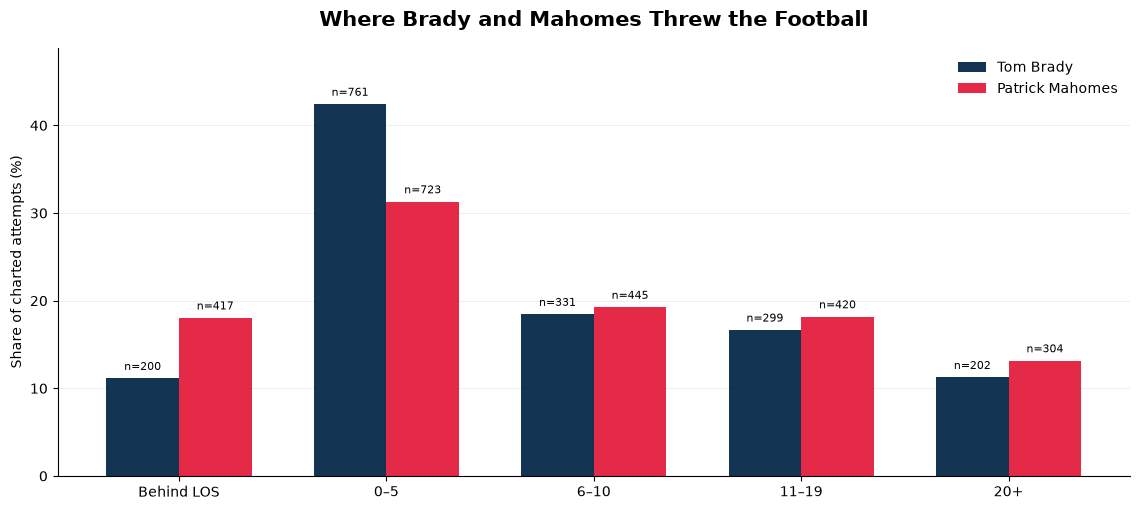

In [3]:
def grouped_bars(metric, ylabel, title, filename, display_n=False, zero_line=False):
    x = np.arange(len(ORDER))
    width = 0.35
    fig, ax = plt.subplots(figsize=(11.5, 5.2))
    for i, player in enumerate(PLAYERS):
        piece = summary[summary.player_name.eq(player)].set_index("depth_zone").reindex(ORDER)
        vals = piece[metric].to_numpy(dtype=float)
        xpos = x + (i - .5)*width
        ax.bar(xpos, vals, width=width, color=COLORS[player], label=player, alpha=.92)
        if display_n:
            for j, val in enumerate(vals):
                ax.annotate(f"n={int(piece.iloc[j]['attempts'])}",
                            (xpos[j],val),ha="center",va="bottom",fontsize=8,
                            xytext=(0,4), textcoords="offset points")
    if zero_line:
        ax.axhline(0, linewidth=1, color="#586577")
    ax.set_xticks(x, ORDER)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=15, fontweight="bold", pad=16)
    ax.legend(frameon=False, loc="upper right")
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
    ax.spines[["top","right"]].set_visible(False)
    ax.margins(y=.15)
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=300, bbox_inches="tight")
    plt.show()

grouped_bars("attempt_share_pct", "Share of charted attempts (%)",
             "Where Brady and Mahomes Threw the Football",
             "14_pass_depth_attempt_share.png", display_n=True)

## 4. Observed completion percentage by depth

Completion rates usually decrease with depth. This comparison is *descriptive* and does not yet account for the difference in modeled throw difficulty; the next section does.

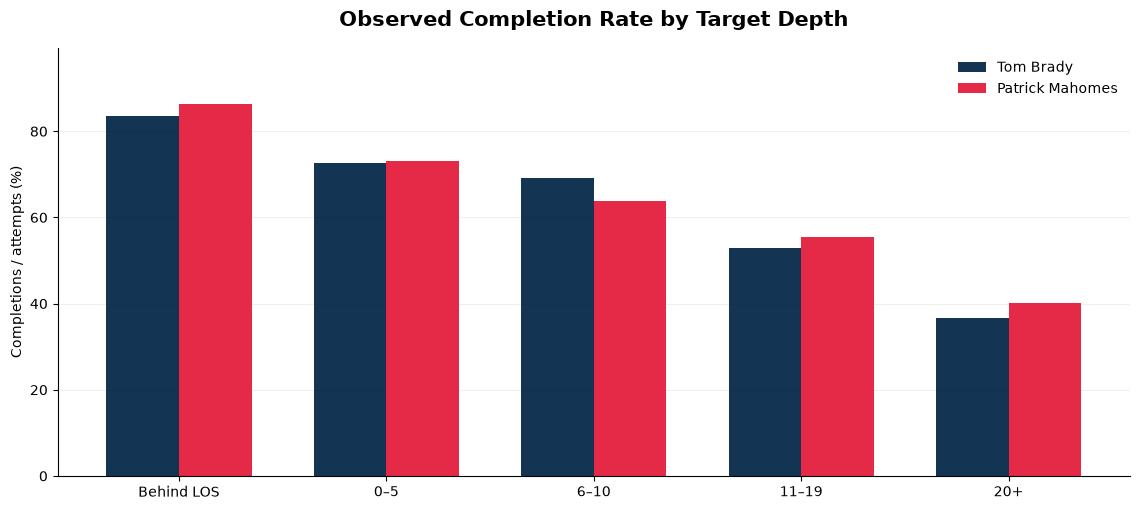

In [4]:
grouped_bars("completion_pct", "Completions / attempts (%)",
             "Observed Completion Rate by Target Depth",
             "15_pass_depth_completion_pct.png")

## 5. QB EPA per pass attempt by depth

This is **QB EPA on passes only**, divided by the number of eligible attempts in each zone. It is not equivalent to the EPA per dropback metrics in notebook 03: sacks and scrambles do not have meaningful throw depth and are not assigned to zones.

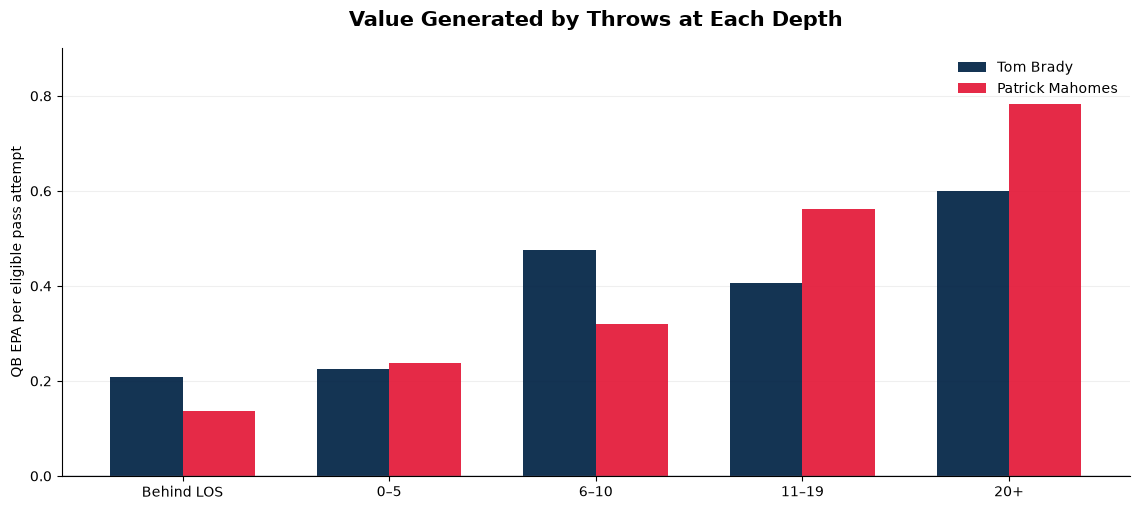

In [5]:
grouped_bars("qb_epa_per_attempt", "QB EPA per eligible pass attempt",
             "Value Generated by Throws at Each Depth",
             "16_pass_depth_qb_epa_per_attempt.png", zero_line=True)

## 6. Completion Percentage Over Expected (CPOE) — primary analysis

**Interpretation:** CPOE compares actual completion outcomes to `cp`, the nflfastR model's expected completion probability for each modeled throw. Values are expressed in **percentage points**.

A value of **+5 pp** means the observed completion percentage exceeded the model's average expectation by five percentage points *within the modeled sample*; it does not mean five percent more throws, five percent extra EPA, or proof that the quarterback alone caused the difference.

We compute exploratory uncertainty intervals by **resampling whole games**, not individual throws. This respects within-game dependence better than treating each pass as independent. These are descriptive bootstrap intervals, not causal confidence statements.

,player_name,depth_zone,modeled_attempts,cpoe_pp,ci_low,ci_high,cp_coverage_pct
0,Patrick Mahomes,Behind LOS,410,2.59,-1.13,6.05,98.32
1,Patrick Mahomes,0–5,688,4.59,1.26,8.11,95.16
2,Patrick Mahomes,6–10,432,-0.10,-4.44,3.86,97.08
3,Patrick Mahomes,11–19,395,2.55,-2.55,7.80,94.05
4,Patrick Mahomes,20+,296,5.93,-0.06,11.73,97.37
5,Tom Brady,Behind LOS,193,4.42,-0.20,8.69,96.50
6,Tom Brady,0–5,750,4.98,1.67,8.19,98.55
7,Tom Brady,6–10,328,8.04,3.42,12.52,99.09
8,Tom Brady,11–19,297,-0.39,-6.06,5.74,99.33
9,Tom Brady,20+,199,4.23,-1.71,11.12,98.51


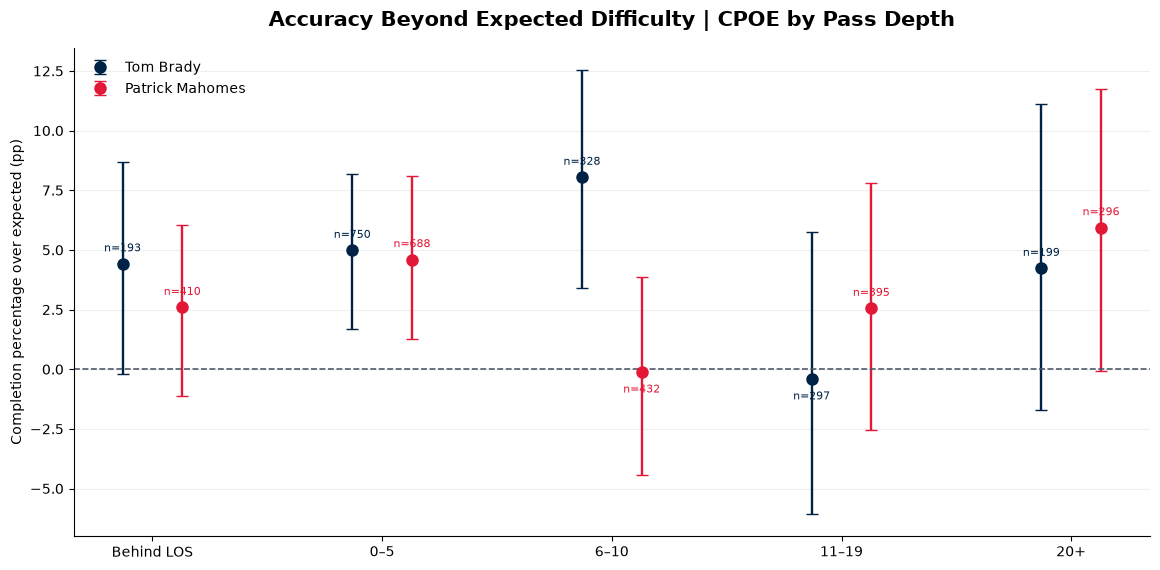

In [6]:
def game_cluster_cpoe_intervals(games_df, repetitions=3000, seed=2026):
    rng = np.random.default_rng(seed)
    rows = []
    for player in PLAYERS:
        data = games_df[games_df.player_name == player]
        ids = np.array(sorted(data.game_id.unique()))
        draws = rng.integers(0, len(ids), size=(repetitions, len(ids)))
        for zone in ORDER:
            z = data[data.depth_zone == zone].set_index("game_id")
            denominators = z.reindex(ids)["modeled_attempts"].fillna(0).to_numpy(dtype=float)
            numerators = z.reindex(ids)["sum_cpoe_pp"].fillna(0).to_numpy(dtype=float)
            sampled_n = denominators[draws].sum(axis=1)
            sampled_sum = numerators[draws].sum(axis=1)
            boot = np.divide(sampled_sum, sampled_n,
                             out=np.full(repetitions, np.nan), where=sampled_n > 0)
            valid = boot[np.isfinite(boot)]
            low, high = np.quantile(valid, [.025, .975]) if len(valid) else (np.nan, np.nan)
            rows.append({"player_name": player, "depth_zone": zone,
                         "ci_low": low, "ci_high": high, "games": len(ids)})
    return pd.DataFrame(rows)

intervals = game_cluster_cpoe_intervals(games)
results = summary.merge(intervals, on=["player_name", "depth_zone"], validate="one_to_one")

display(results[["player_name", "depth_zone", "modeled_attempts", "cpoe_pp",
                 "ci_low", "ci_high", "cp_coverage_pct"]].round(2))

fig, ax = plt.subplots(figsize=(11.7, 5.8))
x = np.arange(len(ORDER))
for i, player in enumerate(PLAYERS):
    piece = results[results.player_name.eq(player)].set_index("depth_zone").reindex(ORDER)
    y = piece.cpoe_pp.to_numpy(float)
    lows = piece.ci_low.to_numpy(float)
    highs = piece.ci_high.to_numpy(float)
    x_pos = x + (-.13 if i == 0 else .13)
    ax.errorbar(x_pos, y, yerr=[np.maximum(y-lows, 0), np.maximum(highs-y, 0)],
                fmt="o", ms=8, capsize=4, elinewidth=1.7, color=COLORS[player],
                label=player, linewidth=0)
    for xi, yi, n in zip(x_pos, y, piece.modeled_attempts):
        ax.annotate(f"n={int(n)}", (xi, yi), fontsize=8, color=COLORS[player],
                    xytext=(0, 9 if yi>=0 else -15), textcoords="offset points", ha="center")
ax.axhline(0, color="#495363", linewidth=1.15, linestyle="--")
ax.set_xticks(x, ORDER)
ax.set_ylabel("Completion percentage over expected (pp)")
ax.set_title("Accuracy Beyond Expected Difficulty | CPOE by Pass Depth",
             fontsize=15, fontweight="bold", pad=16)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "17_pass_depth_cpoe_with_game_bootstrap.png", dpi=300, bbox_inches="tight")
plt.show()

results.to_csv("../reports/pass_depth_cpoe_summary_with_intervals.csv", index=False)

### Actual versus expected completions — identical modeled attempts

This graph decomposes the CPOE result. **Observed completion on the modeled subset** and the **mean expected completion** use the same set of throws. Do not compare the expected rate here with the broader all-throws completion rate above: the denominators can differ.

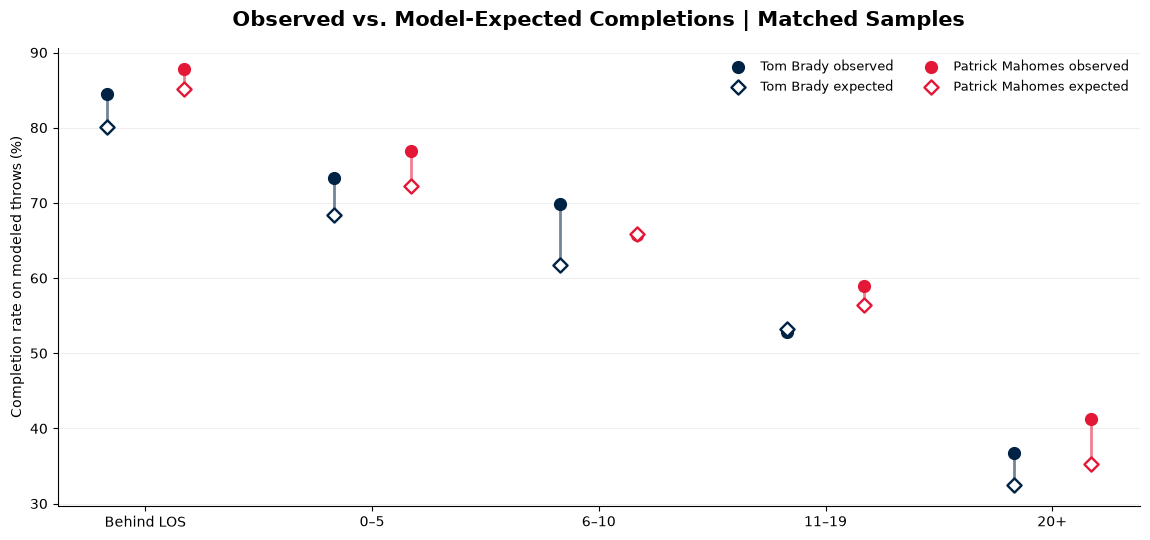

In [7]:
fig, ax = plt.subplots(figsize=(11.6, 5.5))
x = np.arange(len(ORDER))
for player, offset in (("Tom Brady", -.17), ("Patrick Mahomes", .17)):
    z = summary[summary.player_name.eq(player)].set_index("depth_zone").reindex(ORDER)
    actual = z.modeled_completion_pct.to_numpy(float)
    expected = z.expected_completion_pct.to_numpy(float)
    xpos = x+offset
    for xi, lo, hi in zip(xpos, expected, actual):
        ax.plot([xi,xi], [lo,hi], color=COLORS[player], alpha=.55, lw=2)
    ax.scatter(xpos, actual, marker="o", s=72, color=COLORS[player],
               label=f"{player} observed", zorder=3)
    ax.scatter(xpos, expected, marker="D", s=52, facecolors="white",
               edgecolors=COLORS[player], linewidths=1.7,
               label=f"{player} expected", zorder=3)
ax.set_xticks(x, ORDER)
ax.set_ylabel("Completion rate on modeled throws (%)")
ax.set_title("Observed vs. Model-Expected Completions | Matched Samples",
             fontsize=15, fontweight="bold", pad=16)
ax.legend(frameon=False, ncol=2, fontsize=9)
ax.grid(axis="y", alpha=.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "18_observed_vs_expected_completion_depth.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. How much does CPOE availability vary by zone?

The full study has **4,103** official pass attempts, **4,102** with charted depth, and **3,988** usable for CPOE. CPOE is available on ~98.6% of Brady attempts versus ~96.1% of Mahomes attempts. Missing predictions need not be random; do not interpret small CPOE differences as conclusive without checking coverage patterns.

In [8]:
missingness = (summary.assign(cp_missing=lambda d:d.attempts-d.modeled_attempts)
               [["player_name","depth_zone","attempts","modeled_attempts","cp_missing","cp_coverage_pct"]]
               .sort_values(["player_name","depth_zone"]))
display(missingness.round(2))

# Season-specific small samples should not dictate pooled conclusions.
season_view = seasons[["player_name", "season", "depth_zone", "attempts",
                       "modeled_attempts", "cpoe_pp", "qb_epa_per_attempt"]]
print("Small-sample (N<30) seasonal cells:")
display(season_view[season_view.modeled_attempts < 30]
        .sort_values(["player_name","season","depth_zone"]).round(2))

,player_name,depth_zone,attempts,modeled_attempts,cp_missing,cp_coverage_pct
1,Patrick Mahomes,0–5,723,688,35,95.16
3,Patrick Mahomes,11–19,420,395,25,94.05
4,Patrick Mahomes,20+,304,296,8,97.37
2,Patrick Mahomes,6–10,445,432,13,97.08
0,Patrick Mahomes,Behind LOS,417,410,7,98.32
6,Tom Brady,0–5,761,750,11,98.55
8,Tom Brady,11–19,299,297,2,99.33
9,Tom Brady,20+,202,199,3,98.51
7,Tom Brady,6–10,331,328,3,99.09
5,Tom Brady,Behind LOS,200,193,7,96.50


Small-sample (N<30) seasonal cells:


,player_name,season,depth_zone,attempts,modeled_attempts,cpoe_pp,qb_epa_per_attempt
31,Tom Brady,2008,0–5,5,5,-26.95,-0.36
33,Tom Brady,2008,11–19,2,2,-7.19,0.29
34,Tom Brady,2008,20+,1,1,77.33,1.49
32,Tom Brady,2008,6–10,1,1,27.31,0.43
30,Tom Brady,2008,Behind LOS,2,2,15.96,-0.33
43,Tom Brady,2010,11–19,16,16,-20.06,0.18
44,Tom Brady,2010,20+,13,13,0.64,0.32
42,Tom Brady,2010,6–10,20,19,1.24,0.47
40,Tom Brady,2010,Behind LOS,12,12,16.68,0.05


## 8. Key questions and interpretation checklist

Before writing conclusions, record numerical answers to:

1. Where is each quarterback's **attempt share** concentrated? Do they target different depths?
2. Are the **completion rates** different because attempts are more/less difficult, or does **CPOE** also differ?
3. Which depths contribute the most **QB EPA per throw**, and does this align with accuracy?
4. How many **modeled attempts** underlie each CPOE estimate, especially deep throws?
5. Are CPOE contrasts stable enough relative to the **game-cluster bootstrap intervals** to warrant strong language?

### Methodological boundaries

- CPOE is a **model-dependent descriptive residual**, not an isolation of QB talent or improvisation. Receiver skill, coverage, pressure, and era-specific model calibration may matter.
- Passing EPA by depth excludes sacks/scrambles, so it is **not** a decomposition of total quarterback dropback EPA from notebook 03.
- Brady has 53 selected starts and Mahomes 62; reported pooled metrics are **attempt-weighted**, not season-weighted.
- Brady 2008 has only 11 pass attempts: high single-game CPOE by zone is extremely unstable; Brady 2010 includes only four selected starts.
- The sample was chosen based on CPOE coverage and roster-context research questions, not a validated estimate of either QB's objectively best peak.
- One Mahomes 2020 throw lacks air yards; other throws lack `cp`. No values are invented for either.

**Follow-up research:** Check season/era calibration of completion probability and assess whether CPOE differences persist under alternative period definitions and more targeted opponent/context controls.